# Classification Project

In this project, you will work with the breast cancer dataset again and use different classification models. The goal is to predict whether we are in a case malignant or benign. You will use things you have learned from cross-validation and from hyperparameter search.

## Part 0 - Importing the Dataset

The cell below imports the relevant libraries you need and imports the breast cancer dataset. Run the cell below without modifying it, and then you can proceed.

In [45]:
# Non-sklearn packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn packages
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

# Getting the data and targets
X = pd.DataFrame(load_breast_cancer()['data'], columns=load_breast_cancer()['feature_names'])
y = pd.DataFrame(load_breast_cancer()['target'], columns=["target"])

# Printing out description of the dataset
print(load_breast_cancer()['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

## Part 1 - Exploring the Dataset

When exploring the data, it is good to have the features and targets in a single dataframe. Combine the variables `X` and `y` into a single dataframe called `combined`:

In [46]:
# Combine into a single dataframe
combined= pd.concat([X,y], axis=1)

In [47]:
# Show the first rows of the dataframe
combined.tail(10)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
559,11.51,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.04105,0.1388,0.06570,...,37.16,82.28,474.2,0.12980,0.25170,0.3630,0.09653,0.2112,0.08732,1
560,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,0.1537,0.06171,...,33.17,100.20,706.7,0.12410,0.22640,0.1326,0.10480,0.2250,0.08321,1
561,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,0.1060,0.05502,...,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905,1
562,15.22,30.62,103.40,716.9,0.10480,0.20870,0.25500,0.09429,0.2128,0.07152,...,42.79,128.70,915.0,0.14170,0.79170,1.1700,0.23560,0.4089,0.14090,0
563,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,0.2149,0.06879,...,29.41,179.10,1819.0,0.14070,0.41860,0.6599,0.25420,0.2929,0.09873,0
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.22160,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.16280,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.14180,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.26500,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.00000,0.2871,0.07039,1


In [48]:
# Get summary statistics for the columns
combined.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [49]:
# Check if there are any missing values
combined.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [50]:
# How many of the patients are in the class "malignant" or "benign"
combined['target'].value_counts() 

target
1    357
0    212
Name: count, dtype: int64

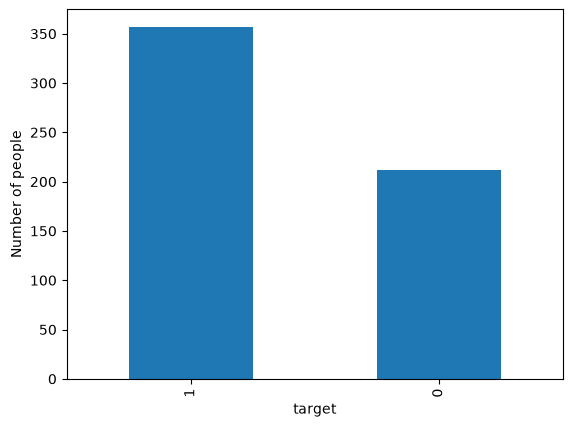

In [51]:
# Visualize with a bar chart how many of the patients are in the class "malignant" or "benign"
combined['target'].value_counts().plot(kind='bar')
plt.ylabel('Number of people')
plt.show()

In [52]:
# Check the correlation of the combined dataframe
combined.corr()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
mean radius,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,...,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066,-0.730029
mean texture,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,...,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205,-0.415185
mean perimeter,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,...,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019,-0.742636
mean area,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,...,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738,-0.708984
mean smoothness,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,...,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316,-0.358560
mean compactness,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,...,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382,-0.596534
mean concavity,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,...,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930,-0.696360
mean concave points,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,...,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661,-0.776614
mean symmetry,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,...,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413,-0.330499
mean fractal dimension,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,...,-0.051269,-0.205151,-0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297,0.012838


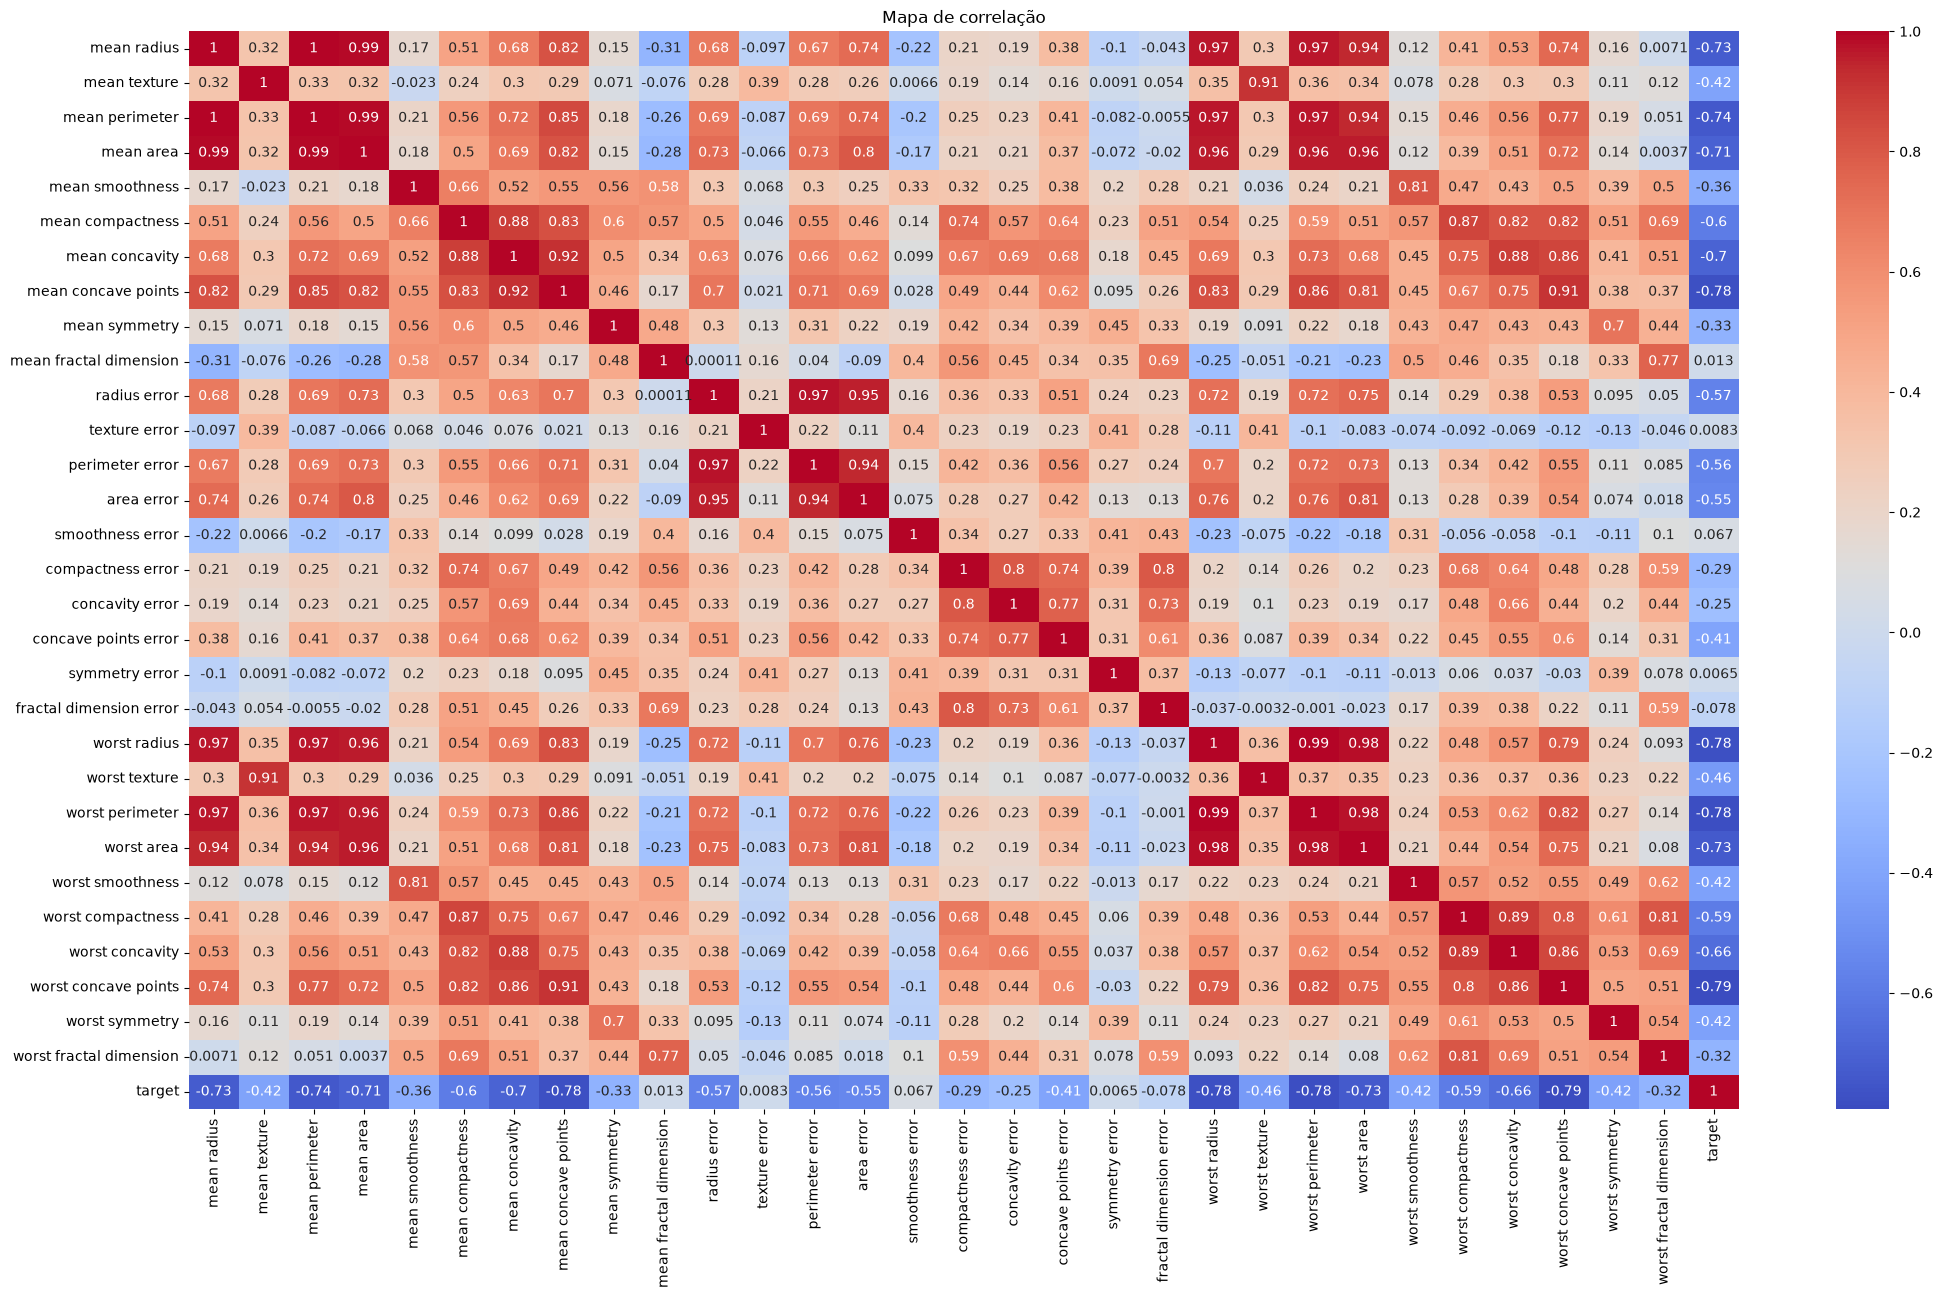

In [77]:
# Plot the correlation of combined with a heatmap (HINT: sns.heatmap

plt.figure(figsize=(25, 14))
sns.heatmap(combined.corr(), annot=True, cmap="coolwarm")
plt.title("Mapa de correlação")
plt.show()

Which features looks to be highly correlated with the target?

## Part 2 - Preprocessing

It is now time to start preprocessing the dataset. There are no missing values, so we only need to normalize the data. Before doing this, we should create a test set (since we are planning to evaluate our final chosen model on this). Doing this BEFORE any data processing allows us to avoid data leakage. 

We do not need the variable `combined` anymore and we can stick to `X` and `y` variables. Let us first separate 10% of the dataset by using `train_test_split`:

In [57]:
# Separate 10% of the dataset
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.1,random_state=42)

Now we can use StandardScaler individually on the main part and the test data set. We DO NOT need to scale the variables target variables.

In [58]:
# Use StandardScaler to scale both the main part, and the test set

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

The shape of the targets indicate that they are two-dimensional NumPy arrays. But for the `GridSearchCV` class that we will use later, it is required that they be one-dimensional. Use `np.ravel` to flatten the targets to be one-dimensional:

In [59]:
# Flatten the targets
# Flatten the targets
y_train = np.ravel(y_train)
y_test = np.ravel(y_test)

## Part 3 - Random Forests and Hyperparameters

In this section we will create a random forest with different amount of decision trees in them. The goal is to get experience with hyperparameter search with a single hyperparameter.

In [60]:
# Create a random forest classifier
randomc= RandomForestClassifier()

The `RandomForestClassifier` class has a `n_estimators` hyperparameter that decides the number of decision trees in the model. Create a Python dictionary called `param_grid_forest` that specifies the values `1` `2`, `5`, `10`, `20`, `50`, `100`, `200`, `500`, `1000` for the `n_estimators` hyperparameter.

In [78]:
# Specify the Python dictionary with the n_estimators key
param_grid_forest = {"n_estimators": [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]}
# Use GridSearchCV on the random forest model with the param_grid set to the above Python dictionary
grid_forest = GridSearchCV(randomc, param_grid=param_grid_forest,cv=5)

In [79]:
# Fit the GridSearchCV model to the data
grid.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_estimators': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with hig

In [ ]:
# Check out the results
best=grid.best_estimator_


np.float64(0.9628783552255854)

In [87]:
# Get the best score
best.score(X_test,y_test)

0.9649122807017544

In [89]:
# Predict on the scaled test data
y_pred=best.predict(X_test)

In [90]:
# Get the accuracy for the best forest
accuracy= accuracy_score(y_pred,y_test)
print(accuracy)
# Get the precision for the best forest
precision=precision_score(y_pred,y_test)
print(precision)
# Get the recall for the best forest
recall=recall_score(y_pred,y_test)
print(recall)

0.9649122807017544
0.975
0.975


## Part 4 - SVMs and Hyperparameters

In this section we will create a support vector machine with values for the `C` hyperparameter and the `degree` hyperparameter. The goal is to get experience with hyperparameter search with two hyperparameters.

In [91]:
# Create a support vector machine with kernel equal to "poly"
svm_model=SVC(kernel='poly')

The `SVC` class has a `C` hyperparameter and a `degree` hyperparameter (whenever we specify that the `kernel` should be `poly`). Create a Python dictionary called `param_grid_svc` that specifies the values `1` `2`, `5`, `10` for the `C` hyperparameter, and the values `1`, `2`, `3`, `4` for the `degree` hyperparameter.

In [95]:
# Specify the Python dictionary with the C and degree keys
param_grid_svc ={'C':[1,2,5,10],'degree':[1,2,3,4]}
# Use GridSearchCV on the SVC model with the param_grid set to the above Python dictionary
grid_svc =GridSearchCV(svm_model,param_grid=param_grid_svc,cv=5)

In [96]:
# Fit the GridSearchCV model to the data
grid_svc.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(kernel='poly')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [1, 2, ...], 'degree': [1, 2, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with 

In [110]:
# Check out the results

pd.DataFrame(grid_svc.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_degree,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.002984,0.001316,0.001188,0.000305,1,1,"{'C': 1, 'degree': 1}",0.980583,0.970874,0.970588,0.990196,0.970588,0.976566,0.007820,3
1,0.006325,0.000978,0.002200,0.000213,1,2,"{'C': 1, 'degree': 2}",0.844660,0.805825,0.823529,0.754902,0.784314,0.802646,0.031071,15
2,0.003377,0.000834,0.001580,0.000784,1,3,"{'C': 1, 'degree': 3}",0.922330,0.864078,0.921569,0.931373,0.872549,0.902380,0.028156,8
3,0.004155,0.000110,0.001229,0.000041,1,4,"{'C': 1, 'degree': 4}",0.825243,0.805825,0.813725,0.735294,0.794118,0.794841,0.031458,16
4,0.001893,0.000111,0.000810,0.000032,2,1,"{'C': 2, 'degree': 1}",0.980583,0.980583,0.970588,0.990196,0.980392,0.980468,0.006201,1
5,0.004172,0.000183,0.001238,0.000071,2,2,"{'C': 2, 'degree': 2}",0.854369,0.825243,0.862745,0.784314,0.803922,0.826118,0.029600,11
6,0.002514,0.000205,0.001053,0.000065,2,3,"{'C': 2, 'degree': 3}",0.941748,0.902913,0.931373,0.941176,0.892157,0.921873,0.020496,7
7,0.004862,0.000421,0.001581,0.000267,2,4,"{'C': 2, 'degree': 4}",0.825243,0.805825,0.833333,0.774510,0.784314,0.804645,0.022672,14
8,0.002423,0.000370,0.001041,0.000153,5,1,"{'C': 5, 'degree': 1}",0.990291,0.970874,0.970588,1.000000,0.960784,0.978508,0.014394,2
9,0.004627,0.000131,0.001234,0.000068,5,2,"{'C': 5, 'degree': 2}",0.873786,0.844660,0.892157,0.823529,0.813725,0.849572,0.029621,10


In [109]:
# Get the best score
grid_svc.best_estimator_.score(X_test,y_test)

0.9824561403508771

In [112]:

bestsvc=grid_svc.best_estimator_

In [115]:
# Predict on the scaled test data
y_predsvc =bestsvc.predict(X_test)

In [117]:
# Get the accuracy for the best SVC
accuracy=accuracy_score(y_predsvc,y_test)
print(accuracy)
# Get the precision for the best SVC
precision=precision_score(y_predsvc,y_test)
print(precision)
# Get the recall for the best SVC
recall=recall_score(y_predsvc,y_test)
print(recall)

0.9824561403508771
1.0
0.975609756097561


What conclusions can you draw form the results? Should you continue with the support vector machine, or the random forest?